# Лабораторная работа 1. Генерация и первичный анализ временных рядов

Цель — реализовать генератор с шагом 5 минут и исследовать качество почасового ряда. Первая часть соответствует ts_lab_1, вторая — практике TS_1. Все данные синтетические.

## Генератор с шагом 5 минут

In [1]:
import csv
from datetime import datetime, timedelta
from itertools import count
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 85, "savefig.dpi": 110})

VARIANCE = ("const", "grow", "decay")
SLOPES = {"none": 0, "fast_up": 45, "slow_up": 15,
          "fast_down": -45, "slow_down": -15}
CYCLES = {"none": (), "one": (12,), "two": (12, 72)}

def choose(mode, options, rng):
    if mode == "random":
        return str(rng.choice(list(options)))
    if mode not in options:
        raise ValueError(f"Неизвестный режим {mode!r}. Варианты: {', '.join(options)}, random")
    return mode

def generate_series(n=1000, variance="const", trend="none", seasonality="none", seed=None):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("Количество точек должно быть положительным целым числом")
    rng = np.random.default_rng(seed)
    variance = choose(variance, VARIANCE, rng)
    trend = choose(trend, SLOPES, rng)
    seasonality = choose(seasonality, CYCLES, rng)
    midnight = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    t = np.arange(n)
    position = t / max(n - 1, 1)
    noise_variance = {"const": 4, "grow": 1 + 24 * position,
                      "decay": 25 - 24 * position}[variance]
    values = 100 + SLOPES[trend] * position + rng.normal(size=n) * np.sqrt(noise_variance)
    for period, amplitude in zip(CYCLES[seasonality], (5, 9)):
        values += amplitude * np.sin(2 * np.pi * t / period)
    timestamps = [midnight + timedelta(minutes=5 * int(i)) for i in t]
    return timestamps, values, (variance, trend, seasonality)

def save_csv(timestamps, values, directory="generated"):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    prefix = datetime.now().strftime("ts_%Y%m%d_%H%M%S")
    for i in count():
        suffix = f"_{i}" if i else ""
        path = directory / f"{prefix}{suffix}.csv"
        try:
            with path.open("x", encoding="utf-8", newline="") as file:
                writer = csv.writer(file)
                writer.writerow(("timestamp", "value"))
                writer.writerows((stamp.isoformat(" "), f"{value:.6f}")
                                 for stamp, value in zip(timestamps, values, strict=True))
            return path
        except FileExistsError:
            continue

Дисперсия шума меняется линейно между заданными уровнями, а стандартное отклонение равно её квадратному корню. Тренд задаёт изменение уровня на всём интервале. Сезонность с периодами 12 и 72 отсчёта даёт циклы длиной 1 и 6 часов.

In [2]:
random_times, random_values, modes = generate_series(
    variance="random", trend="random", seasonality="random", seed=37)
csv_path = save_csv(random_times, random_values)
print(f"Случайные режимы (дисперсия, тренд, сезонность): {modes}")
print(f"{len(random_values)} точек, CSV: {csv_path}")
assert random_times[0].time() == datetime.min.time()
assert all(b - a == timedelta(minutes=5) for a, b in zip(random_times, random_times[1:]))
with csv_path.open(encoding="utf-8", newline="") as file:
    rows = list(csv.reader(file))
assert rows[0] == ["timestamp", "value"] and len(rows) == 1001

Случайные режимы (дисперсия, тренд, сезонность): ('const', 'fast_down', 'one')
1000 точек, CSV: generated\ts_20261125_220833.csv


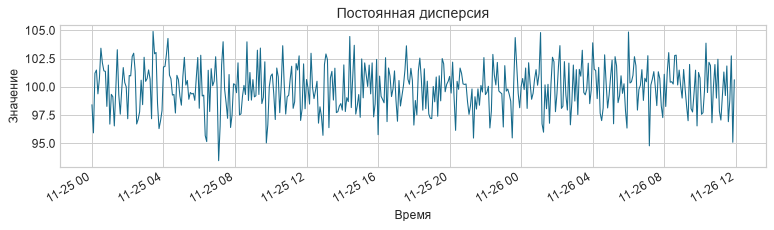

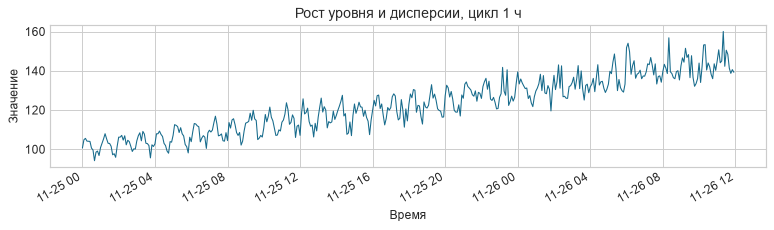

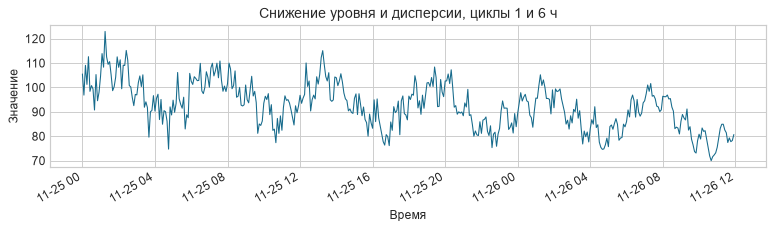

In [3]:
Path("images").mkdir(exist_ok=True)
examples = [
    ("const", "none", "none", "Постоянная дисперсия"),
    ("grow", "fast_up", "one", "Рост уровня и дисперсии, цикл 1 ч"),
    ("decay", "slow_down", "two", "Снижение уровня и дисперсии, циклы 1 и 6 ч"),
]
for i, (variance, trend, seasonality, title) in enumerate(examples, 1):
    dates, values, _ = generate_series(432, variance, trend, seasonality, seed=100 + i)
    fig, ax = plt.subplots(figsize=(9, 2.6), layout="constrained")
    ax.plot(dates, values, lw=0.9, color="#176b8c")
    ax.set(title=title, xlabel="Время", ylabel="Значение")
    fig.autofmt_xdate()
    fig.savefig(f"images/lab_image_{i}.png")
    plt.show()

## Первичный анализ почасового ряда

Моделируем показания датчика за восемь недель. В исходный CSV добавляем повтор строки, одиночные пропуски, два блока пропусков и три экстремальных значения. Одно из них моделирует реальное событие, два — ошибку датчика. В реальных данных для такого различия понадобятся журнал событий или независимые измерения.

In [4]:
from io import StringIO
import pandas as pd

rng = np.random.default_rng(101)
index = pd.date_range("2026-01-05", periods=8 * 168, freq="h")
t = np.arange(len(index))
clean = 100 + 0.012 * t + 6 * np.sin(2 * np.pi * t / 24)
clean += 4 * np.cos(2 * np.pi * t / 168) + rng.normal(0, 1.4, len(t))
observed = pd.DataFrame({"timestamp": index, "value": clean})
events = {213: (40, "ошибка датчика"), 579: (-50, "ошибка датчика"),
          1110: (49, "реальное событие")}
for i, (offset, _) in events.items():
    observed.loc[i, "value"] += offset
observed.loc[[85, 681, 999, *range(313, 323), *range(845, 850)], "value"] = np.nan
raw = pd.concat([observed.dropna(), observed.iloc[[11]]]).sample(frac=1, random_state=3)
frame = pd.read_csv(StringIO(raw.to_csv(index=False)), parse_dates=["timestamp"])
duplicates = frame["timestamp"].duplicated().sum()
y = (frame.sort_values("timestamp").drop_duplicates("timestamp")
     .set_index("timestamp")["value"].asfreq("h"))
print(f"Дубликаты: {duplicates}. Частота: {y.index.freqstr}. Пропуски: {y.isna().sum()} / {len(y)}.")
absent = y.isna()
runs = absent.ne(absent.shift(fill_value=False)).cumsum()
gaps = absent[absent].groupby(runs[absent]).apply(
    lambda group: pd.Series({"Начало": group.index.min(), "Конец": group.index.max(),
                             "Длина": len(group)})).unstack()
display(gaps.reset_index(drop=True))

Дубликаты: 1. Частота: h. Пропуски: 18 / 1344.


,Начало,Конец,Длина
0,2026-01-08 13:00:00,2026-01-08 13:00:00,1
1,2026-01-18 01:00:00,2026-01-18 10:00:00,10
2,2026-02-02 09:00:00,2026-02-02 09:00:00,1
3,2026-02-09 05:00:00,2026-02-09 09:00:00,5
4,2026-02-15 15:00:00,2026-02-15 15:00:00,1


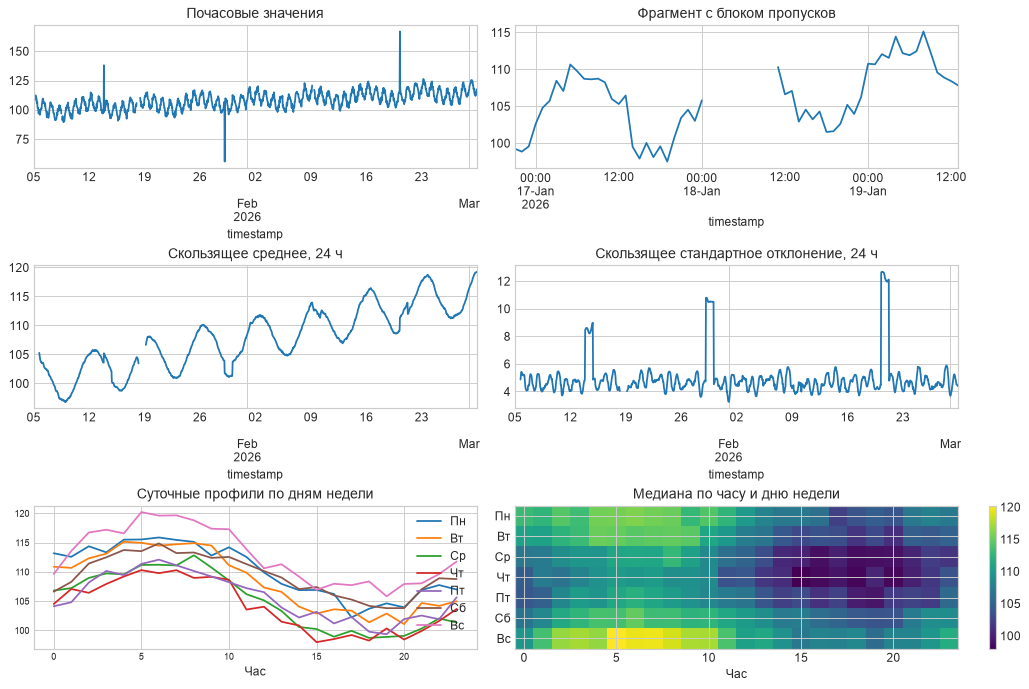

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), layout="constrained")
y.plot(ax=axes[0, 0], title="Почасовые значения")
y.iloc[285:350].plot(ax=axes[0, 1], title="Фрагмент с блоком пропусков")
y.rolling(24, min_periods=18).mean().plot(ax=axes[1, 0], title="Скользящее среднее, 24 ч")
y.rolling(24, min_periods=18).std().plot(ax=axes[1, 1], title="Скользящее стандартное отклонение, 24 ч")
profile = y.groupby([y.index.day_of_week, y.index.hour]).median().unstack()
profile.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
profile.T.plot(ax=axes[2, 0], title="Суточные профили по дням недели", xlabel="Час", fontsize=8)
heatmap = axes[2, 1].imshow(profile, aspect="auto", cmap="viridis")
axes[2, 1].set(yticks=range(7), yticklabels=profile.index, xlabel="Час",
               title="Медиана по часу и дню недели")
fig.colorbar(heatmap, ax=axes[2, 1])
plt.show()

In [6]:
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
local_median = y.rolling(49, center=True, min_periods=24).median()
local_mad = y.rolling(49, center=True, min_periods=24).apply(
    lambda x: np.nanmedian(np.abs(x - np.nanmedian(x))), raw=True)
flags = pd.DataFrame({
    "IQR": (y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr),
    "z-score": ((y - y.mean()) / y.std()).abs() > 3,
    "rolling MAD": (y - local_median).abs() > 4.5 * 1.4826 * local_mad,
})
outliers = flags.loc[flags.any(axis=1)].copy()
outliers["Значение"] = y.round(2)
outliers["Происхождение"] = [events.get(y.index.get_loc(stamp), (0, "обычное наблюдение"))[1]
                              for stamp in outliers.index]
display(outliers)

# Ошибки датчика исключаем из ряда. Реальное событие сохраняем.
analysis_y = y.drop(index=index[[213, 579]]).asfreq("h")
# Скрываем известные значения, включая блок, вдали от границ.
blocks = np.arange(700, 712)
eligible = np.setdiff1d(np.arange(168, len(y) - 24), np.r_[blocks, list(events)])
eligible = eligible[analysis_y.iloc[eligible].notna()]
hidden = index[np.sort(np.r_[blocks, rng.choice(eligible, 45, replace=False)])]
masked = analysis_y.drop(index=hidden).asfreq("h")
filled = pd.DataFrame({
    "ffill": masked.ffill(),
    "Интерполяция": masked.interpolate(method="time"),
    "Медиана": masked.fillna(masked.median()),
    "Seasonal Naive (24 ч)": masked.fillna(masked.shift(24)).fillna(masked.median()),
})
errors = filled.loc[hidden].sub(analysis_y.loc[hidden], axis=0)
scores = pd.DataFrame({"MAE": errors.abs().mean(), "RMSE": errors.pow(2).mean().pow(0.5)})
display(scores.sort_values("MAE").round(3))
print(f"Минимальная MAE при искусственном маскировании: {scores['MAE'].idxmin()}.")

,IQR,z-score,rolling MAD,Значение,Происхождение
timestamp,,,,,
2026-01-13 21:00:00,True,True,True,138.03,ошибка датчика
2026-01-29 03:00:00,True,True,True,55.94,ошибка датчика
2026-02-20 06:00:00,True,True,True,166.82,реальное событие


,MAE,RMSE
Интерполяция,1.483,1.881
ffill,2.555,3.657
Seasonal Naive (24 ч),3.224,4.134
Медиана,5.080,6.588


Минимальная MAE при искусственном маскировании: Интерполяция.


### Выводы

1. Скользящее среднее показывает рост уровня. Суточные профили и тепловая карта выявляют ежедневный цикл и различия между днями недели.
2. Почасовая сетка выявила как одиночные пропуски, так и непрерывные блоки. Всего найдено 18 пропусков. Самый длинный блок длится 10 часов. Ошибки измерения добавляют ещё два пропуска после очистки.
3. IQR и z-score используют глобальный масштаб, а rolling MAD учитывает локальный уровень. Причину экстремальных значений в этом опыте определяет сценарий генерации.
4. Ошибка импутации рассчитана только на 57 скрытых известных значениях. Линейная интерполяция дала минимальные MAE (1,483) и RMSE (1,881). Линейная интерполяция использует правую границу пропуска и подходит для ретроспективной очистки. Для работы в реальном времени подходят методы, опирающиеся на прошлые наблюдения.